# 3: Student distillation

This notebook trains a small **Student** model to predict heart conditions from ECGs using **distillation**, learning from both the dataset's true labels and a Teacher's predictions. The Student makes predictions on its own after training.

**Before you start:**

- [ ] **Dataset:** unzip EchoNext into `data/echonext/1.1.1/` inside the repo. This folder should contain the metadata CSV and the training/validation waveform and tabular `.npy` files. If the files are elsewhere, set `DATA_DIR` in Part 2 to that folder.
- [ ] **If using a trained Teacher:** have its training prediction folder ready, for example `runs/teacher/train/`. It must contain `predictions.npz`, `metadata.csv`, `manifest.json`, and `metrics.json`. Set `TEACHER_SOURCE = "teacher"` and `TEACHER_TRAIN_RUN` in Part 2 to that folder. A matching validation folder, such as `runs/teacher/val/`, is optional; set `TEACHER_VAL_RUN` if you have it. Teacher weights are not needed.
- [ ] **If using EchoNext-Mini instead:** leave `TEACHER_SOURCE = "mini"`. Part 4 downloads the required Mini files if missing and generates its predictions; you do not need to prepare them yourself.
- [ ] **If using Kaggle:** attach the private EchoNext dataset and turn Internet on. The dataset can stay under `/kaggle/input/`; you do not need to copy it into the repo. Set `DATA_DIR` only if automatic discovery cannot find it.

Output folders are created automatically under `runs/` and `checkpoints/` in the repo unless you change `OUTPUT_ROOT` in Part 2.

The training code is in [`distill.py`](../src/compress_ecg/distill.py). The Student model is built, saved, and loaded in [`student.py`](../src/compress_ecg/student.py).

Run the steps in order:

1. **Set up the repo and Python package.** Find the project locally, or download and install it on Kaggle.
2. **Configure Student training.** Choose the data, Teacher source, training settings, and where to save results.
3. **Get the data ready.** Load the training and validation ECGs and check a small batch.
4. **Get Teacher predictions ready.** Load the trained Teacher's saved predictions, or generate and save Mini's predictions.
5. **Train the Student.** Learn from true labels and Teacher predictions, and save the best model.
6. **Review training progress.** Plot the losses and validation scores.
7. **Evaluate the Student.** Reload the best model and compare it with the Teacher on validation data.

This notebook uses Training and Validation only. Test is reserved for final evaluation. Without Teacher validation predictions, step 7 evaluates the Student alone.

<details>
<summary>Running on Kaggle and keeping results private</summary>

Use a private Kaggle notebook with the private EchoNext dataset attached. Turn Internet on, and make sure the selected repo branch contains the Student code before running.

Keep executed notebooks, patient-level predictions, and checkpoints private. Clear notebook outputs before committing to Git.

</details>


## 1. Set up the repo and Python package

**Run the two code cells below.**

- **On your computer:** they use the project you already downloaded.
- **On Kaggle:** turn Internet on first. They download the project if needed and install its Python package automatically.

If both cells finish without errors, go to Part 2.

<details>
<summary>Setup help and optional settings</summary>

- **If Python says a package is missing on your computer:** in a terminal, open the project folder and run `pip install -e '.[dev]'` using the same Python environment as this notebook. If you created the project's `.venv` environment, select it as the notebook's Python environment.
- **If the notebook cannot find the repo:** set `REPO_DIR` below to the full path of your `compress_ECG` folder.
- **If Kaggle should download a different branch:** change `REPO_BRANCH` before running. This only chooses the branch for a new download; it does not switch an existing checkout.
- **Leave `CODE_COMMIT = None`** unless you need to check that the repo is at a specific Git commit.

</details>


In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys
import time

REPO_DIR = None  # Set explicitly if the repository is elsewhere.
REPO_BRANCH = "sanjay/student"
CODE_COMMIT = None
ON_KAGGLE = Path("/kaggle/working").is_dir()

if REPO_DIR is None:
    REPO_DIR = next(
        (path for path in (Path.cwd(), *Path.cwd().parents)
         if (path / "src/compress_ecg").is_dir() and (path / "pyproject.toml").is_file()),
        None,
    )
if REPO_DIR is None:
    if not ON_KAGGLE:
        raise FileNotFoundError("Set REPO_DIR or open this notebook from the repository")
    REPO_DIR = Path("/kaggle/working/compress_ECG")
REPO_DIR = Path(REPO_DIR).expanduser().resolve()

if not REPO_DIR.exists():
    subprocess.run([
        "git", "clone", "--single-branch", "--branch", REPO_BRANCH,
        "https://github.com/andykimdev/compress_ECG.git", str(REPO_DIR),
    ], check=True)

try:
    CODE_VERSION = subprocess.check_output(
        ["git", "rev-parse", "HEAD"], cwd=REPO_DIR, text=True,
    ).strip()
except (OSError, subprocess.CalledProcessError):
    CODE_VERSION = None
if CODE_COMMIT is not None and CODE_VERSION != CODE_COMMIT:
    raise ValueError("Checkout CODE_COMMIT in your repository before running this notebook")

if ON_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-e", str(REPO_DIR)], check=True)
sys.path.insert(0, str(REPO_DIR / "src"))
print("Repository:", REPO_DIR)
print("Code commit:", CODE_VERSION)


Repository: /Users/sanjaykumar/repos/coms6998/compress_ECG
Code commit: 874b835b903ac79420b13be130da7047efae9871


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

from compress_ecg.baseline import load_mini, MINI_WEIGHTS_SHA256, MINI_SOURCE_SHA256
from compress_ecg.data import (
    EchoNextDataset, LABEL_COLUMNS, SHD_INDEX, METADATA_FILENAMES,
    find_metadata_file, resolve_data_dir,
)
from compress_ecg.distill import train_student
from compress_ecg.predictions import (
    aligned_logits, basic_metrics, load_run, run_dir, sha256_file, write_run,
)
from compress_ecg.student import build_student, load_student


## 2. Configure Student training

**Choose your settings below, then run all six code cells in this section in order.**

- **Trying the notebook first?** Keep the small data limits and Mini as the Teacher. Set `max_epochs = 2` in 2.5 for a quick check.
- **Have trained Teacher predictions?** Select `"teacher"` and enter their folder paths in 2.2.
- **Starting another training run?** Choose a new `EXPERIMENT_NAME` in 2.3.

Check the printed settings in 2.6, then go to Part 3. If you change a setting, rerun all Part 2 code cells so everything stays in sync.


### 2.1 Choose the data


**Set the dataset location and how many ECGs to use, then run the cell.**

- Leave `DATA_DIR = None` if the dataset is in the default folder or attached on Kaggle. Otherwise, enter its folder path.
- Keep the small training and validation limits for a first run. Set both to `None` to use all available training and validation ECGs.
- Keep `SEED` the same when comparing training settings.

<details>
<summary>Setting reference and details</summary>

| Setting | Meaning | When to change it |
|---|---|---|
| `DATA_DIR` | Root folder containing the official dataset files. `None` uses `ECHONEXT_DIR`, the local default, or Kaggle discovery. | Set an explicit path if automatic discovery cannot find the dataset. |
| `TRAIN_LIMIT` | Number of ECGs sampled from the official training split. | Use a small subset to check the workflow; use `None` for the full split. |
| `VAL_LIMIT` | Number of ECGs sampled from the official validation split. | Use `None` for the full split; any subset must contain both SHD classes. |
| `SEED` | Controls subset sampling, student initialization, and training batch order. | Keep fixed when comparing configurations. Changing it also changes sampled subsets. |

The current limits are small development subsets. A quick smoke test can also set `max_epochs = 2` in 2.5. For a full-data run, set both limits to `None`.

</details>


In [ ]:
DATA_DIR = None
TRAIN_LIMIT = 512
VAL_LIMIT = 256
SEED = 42

### 2.2 Choose the Teacher predictions


**Choose one source, then run the cell.**

- **EchoNext-Mini:** leave `TEACHER_SOURCE = "mini"`. Part 4 prepares its predictions for you.
- **Trained Teacher:** set `TEACHER_SOURCE = "teacher"` and point `TEACHER_TRAIN_RUN` to its training prediction folder. Set `TEACHER_VAL_RUN` if you also have validation predictions.
- **Reusing Mini predictions:** keep `MINI_CACHE_NAME` the same unless you change the selected ECGs or seed.

<details>
<summary>Setting reference and details</summary>

| Setting | Meaning | When to change it |
|---|---|---|
| `TEACHER_SOURCE` | `"mini"` uses EchoNext-Mini as a stand-in; `"teacher"` loads saved predictions from the fine-tuned Teacher. | Switch to `"teacher"` when its training predictions are available. |
| `TEACHER_TRAIN_RUN` | Folder containing the Teacher's saved training prediction run. | Required in Teacher mode; leave `None` in Mini mode. |
| `TEACHER_VAL_RUN` | Optional saved Teacher validation run for comparison with the Student. | Set when available. Student validation itself uses the dataset's true labels. |
| `MINI_CACHE_NAME` | Names reusable Mini predictions, independently of the Student experiment name. | Choose a new name if either subset or the sampling seed changes. |

Teacher runs must use the same metadata and cover every selected ECG; they may include extra ECGs. Each run folder contains `predictions.npz`, `metadata.csv`, `manifest.json`, and `metrics.json`.

Mini predictions can be reused when only Student training settings change. Existing caches are checked before reuse; incompatible caches raise an error.

</details>


In [ ]:
TEACHER_SOURCE = "mini"
TEACHER_TRAIN_RUN = None  # Example: Path("/kaggle/input/private-teacher-runs/teacher/train")
TEACHER_VAL_RUN = None
MINI_CACHE_NAME = "mini_smoke_v1"

### 2.3 Name the run and choose where to save it


**Give each new training run a new `EXPERIMENT_NAME`, then run the cell.**

Leave `OUTPUT_ROOT = REPO_DIR` to save results inside the repo, or enter another writable folder. The notebook creates the output folders for you.

<details>
<summary>Setting reference and details</summary>

| Setting | Meaning | When to change it |
|---|---|---|
| `EXPERIMENT_NAME` | Identifies one Student training run and its output folders. | Choose a new name for each run; an existing best checkpoint is not overwritten. |
| `OUTPUT_ROOT` | Parent folder for saved prediction runs and checkpoints. | Defaults to the repository, under `/kaggle/working` on Kaggle. Set another writable location if needed. |

Mini stand-in experiments are grouped under `dummy`; real Teacher experiments use `distillation`. Generated paths appear in 2.6.

</details>


In [ ]:
EXPERIMENT_NAME = "mini_longer_v1"
OUTPUT_ROOT = REPO_DIR

### 2.4 Choose the device and loading settings


**Leave these settings as they are for a first run, then run the cell.**

The notebook uses an NVIDIA GPU if available, otherwise an Apple GPU, otherwise the CPU. If prediction generation runs out of memory, lower `INFERENCE_BATCH_SIZE`. Student training batch size is set separately in 2.5.

<details>
<summary>Setting reference and details</summary>

| Setting | Meaning | When to change it |
|---|---|---|
| `DEVICE` | Automatically selects CUDA, then Apple MPS, then CPU. | Set explicitly to `"cuda"`, `"mps"`, or `"cpu"` to use an available device. |
| `INFERENCE_BATCH_SIZE` | ECGs per batch when generating saved predictions. | Reduce if inference runs out of device memory. This is separate from training batch size. |
| `NUM_WORKERS` | DataLoader worker processes during Student training and validation. Zero loads in the main process. | Increase if loading data is a bottleneck and the environment supports worker processes. |

</details>


In [ ]:
DEVICE = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
INFERENCE_BATCH_SIZE = 64
NUM_WORKERS = 0

### 2.5 Choose how the Student trains


**Set the training options below, then run the cell.**

- **Quick check:** set `max_epochs = 2`.
- **Longer training:** the current settings allow up to 50 epochs, stopping early if validation performance stops improving enough.
- **Comparing settings:** change the values you want to try and give the run a new name in 2.3.

The Student learns from both true labels and Teacher predictions. `hard_label_weight` sets the balance; `temperature` adjusts the Teacher's target probabilities.

<details>
<summary>Setting reference and details</summary>

**Optimization** controls weight updates.

| Setting | Meaning | When to change it |
|---|---|---|
| `batch_size` | ECGs per training update; also used for validation batches. | Reduce for memory limits, or compare batch sizes as a training choice. |
| `learning_rate` | AdamW update step size. | Vary when tuning how quickly the Student learns. |
| `weight_decay` | AdamW regularization that discourages large weights. | Vary when tuning generalization. |

**Distillation** controls the balance between true labels and Teacher supervision.

| Setting | Meaning | When to change it |
|---|---|---|
| `temperature` | Softens Teacher probabilities using `sigmoid(logits / temperature)`; the imitation loss applies the same temperature to Student logits and is scaled by temperature squared. | Compare positive values to tune Teacher supervision. |
| `hard_label_weight` | True-label coefficient in `weight * hard_loss + (1 - weight) * soft_loss`. Missing true labels are masked. | Use `0` for Teacher imitation only, `1` for true labels only, or values between them to combine both. |

**Stopping** uses validation SHD AUROC, not training loss.

| Setting | Meaning | When to change it |
|---|---|---|
| `max_epochs` | Maximum passes through the training subset. Early stopping may end training sooner. | Use `2` for a quick smoke test; allow more for training experiments. |
| `patience` | Epochs without sufficient validation SHD AUROC improvement before stopping. | Increase to allow a longer plateau. |
| `min_delta` | AUROC improvement required to reset patience. | Sets what counts as sufficient progress; `0.001` is 0.1 percentage points. |

Any new highest validation SHD AUROC saves the best checkpoint, even if the improvement is too small to reset patience. The current run allows up to **50 epochs** with **patience 7**.

</details>


In [ ]:
TRAINING = {
    # Optimization
    "batch_size": 32,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,

    # Distillation
    "temperature": 2.0,
    "hard_label_weight": 0.5,

    # Stopping
    "max_epochs": 50,
    "patience": 7,
    "min_delta": 0.001,

    # Execution (configured in 2.4)
    "num_workers": NUM_WORKERS,
}

### 2.6 Check your settings

**Run this cell and review the printed settings.**

Check the data limits, Teacher source, training options, and output folders. If something is wrong, change it above and rerun all Part 2 code cells. Otherwise, go to Part 3.

This cell only checks settings and prepares folder paths. It does not load data or start training.


In [ ]:
if TEACHER_SOURCE not in ("mini", "teacher"):
    raise ValueError("TEACHER_SOURCE must be mini or teacher")
for name in (EXPERIMENT_NAME, MINI_CACHE_NAME):
    if not name or name in (".", "..") or Path(name).name != name:
        raise ValueError("Experiment and cache names must be single folder names")

OUTPUT_ROOT = Path(OUTPUT_ROOT).expanduser().resolve()
run_group = "dummy" if TEACHER_SOURCE == "mini" else "distillation"
RUNS_ROOT = OUTPUT_ROOT / "runs" / run_group / EXPERIMENT_NAME
CHECKPOINT_DIR = OUTPUT_ROOT / "checkpoints" / run_group / EXPERIMENT_NAME
MINI_CACHE_ROOT = OUTPUT_ROOT / "runs" / "dummy" / "mini_cache" / MINI_CACHE_NAME
MINI_DIR = REPO_DIR / "external/IntroECG/7-EchoNext Minimodel"

configuration = {
    "experiment": EXPERIMENT_NAME,
    "data": {
        "directory": str(DATA_DIR) if DATA_DIR is not None else "auto-discover in Part 3",
        "train_limit": TRAIN_LIMIT,
        "val_limit": VAL_LIMIT,
        "seed": SEED,
    },
    "teacher": {
        "source": TEACHER_SOURCE,
        "train_run": str(TEACHER_TRAIN_RUN) if TEACHER_TRAIN_RUN is not None else None,
        "val_run": str(TEACHER_VAL_RUN) if TEACHER_VAL_RUN is not None else None,
        "mini_cache_name": MINI_CACHE_NAME,
    },
    "execution": {
        "device": DEVICE,
        "inference_batch_size": INFERENCE_BATCH_SIZE,
        "num_workers": NUM_WORKERS,
    },
    "training": TRAINING,
    "paths": {
        "output_root": str(OUTPUT_ROOT),
        "prediction_runs": str(RUNS_ROOT),
        "checkpoints": str(CHECKPOINT_DIR),
        "mini_cache": str(MINI_CACHE_ROOT),
        "mini_model": str(MINI_DIR),
    },
}
print(json.dumps(configuration, indent=2))

## 3. Get the training and validation data ready

**Run the cell below.** It finds the dataset, prepares the training and validation examples, and prints the size of a small batch.

- **If the dataset cannot be found:** set `DATA_DIR` in 2.1 to the folder containing the metadata CSV and `.npy` files, rerun Part 2, then try again.
- **If validation contains only one SHD class:** increase `VAL_LIMIT`, or set it to `None`, then rerun Parts 2 and 3.

If the cell finishes without errors, go to Part 4.

<details>
<summary>What is in each example?</summary>

Each ECG has a waveform with 12 leads and 2,500 samples per lead, seven extra features, and 12 labels. A label mask marks which true labels are available so missing labels are not treated as negative answers.

The waveform values are already preprocessed; this loader does not apply extra normalization. Each ECG keeps its original row ID so it can be matched with the right Teacher predictions later, even when training batches are shuffled.

</details>


In [4]:
if DATA_DIR is None:
    if os.environ.get("ECHONEXT_DIR"):
        DATA_DIR = resolve_data_dir()
    elif ON_KAGGLE:
        matches = sorted({
            path.resolve() for name in METADATA_FILENAMES
            for path in Path("/kaggle/input").rglob(name)
        })
        if len(matches) != 1:
            raise ValueError(f"Set DATA_DIR explicitly; found {len(matches)} metadata files")
        DATA_DIR = matches[0].parent
    else:
        DATA_DIR = resolve_data_dir()
DATA_DIR = resolve_data_dir(DATA_DIR)
metadata_path = find_metadata_file(DATA_DIR)
if metadata_path is None:
    raise FileNotFoundError("No metadata CSV in DATA_DIR")
METADATA_HASH = sha256_file(metadata_path)

train = EchoNextDataset(DATA_DIR, "train", limit=TRAIN_LIMIT, seed=SEED)
val = EchoNextDataset(DATA_DIR, "val", limit=VAL_LIMIT, seed=SEED)
if np.unique(val.labels[val.indices, SHD_INDEX]).size != 2:
    raise ValueError("Choose a larger validation subset containing both SHD classes")
batch = next(iter(DataLoader(train, batch_size=min(8, len(train)), shuffle=False)))
print("Training ECGs:", len(train), "| Validation ECGs:", len(val))
print({key: tuple(batch[key].shape) for key in ("waveform", "tabular", "labels", "label_mask")})
print("Label order:", LABEL_COLUMNS)


Training ECGs: 512 | Validation ECGs: 256
{'waveform': (8, 12, 2500), 'tabular': (8, 7), 'labels': (8, 12), 'label_mask': (8, 12)}
Label order: ('lvef_lte_45_flag', 'lvwt_gte_13_flag', 'aortic_stenosis_moderate_or_greater_flag', 'aortic_regurgitation_moderate_or_greater_flag', 'mitral_regurgitation_moderate_or_greater_flag', 'tricuspid_regurgitation_moderate_or_greater_flag', 'pulmonary_regurgitation_moderate_or_greater_flag', 'rv_systolic_dysfunction_moderate_or_greater_flag', 'pericardial_effusion_moderate_large_flag', 'pasp_gte_45_flag', 'tr_max_gte_32_flag', 'shd_moderate_or_greater_flag')


## 4. Get the Teacher predictions ready

**Run the cell below.** What it does depends on the source you chose in 2.2:

- **EchoNext-Mini:** download any missing Mini files, then generate and save predictions. If matching predictions already exist, load those instead.
- **Trained Teacher:** load the prediction folders you provided. You do not need the Teacher's trained weights.

**If you see an incompatible Mini cache error:** choose a new `MINI_CACHE_NAME` in Part 2, rerun Part 2, then try this cell again.

If the cell finishes without errors, go to Part 5.

<details>
<summary>Checks and saved predictions</summary>

The cell checks that predictions match the dataset metadata, use the correct training or validation split, and cover the selected ECGs. Mini predictions must also match the selected ECG order and the expected Mini architecture and weights.

The Student learns from saved raw scores, called logits. It does not need the Teacher model running during training. Mini is released after prediction generation, and its stand-in experiment files stay under `runs/dummy/`.

The Mini architecture file is still required to build the Student; this cell downloads it if missing, even when using trained Teacher predictions.

</details>


In [5]:
source_file = MINI_DIR / "cradlenet/models/resnet1d_tabular.py"
weight_file = MINI_DIR / "models/echonext_multilabel_minimodel/weights.pt"
if not source_file.is_file() or (TEACHER_SOURCE == "mini" and not weight_file.is_file()):
    subprocess.run(
        ["bash", "scripts/download_weights.sh", "--mini-only"],
        cwd=REPO_DIR, check=True,
    )
if sha256_file(source_file) != MINI_SOURCE_SHA256:
    raise ValueError("Mini architecture differs from the pinned release; restore it first")
if TEACHER_SOURCE == "mini" and sha256_file(weight_file) != MINI_WEIGHTS_SHA256:
    raise ValueError("Mini weights differ from the pinned release; restore them first")

reference_run = None
if TEACHER_SOURCE == "mini":
    cached = {}
    mini = None
    try:
        for dataset in (train, val):
            folder = run_dir("mini", dataset.split, MINI_CACHE_ROOT)
            if not folder.exists():
                if mini is None:
                    mini = load_mini(MINI_DIR, device=DEVICE)
                write_run(
                    mini, "mini", dataset, runs_root=MINI_CACHE_ROOT,
                    batch_size=INFERENCE_BATCH_SIZE, device=DEVICE, seed=SEED,
                    weights_sha256=MINI_WEIGHTS_SHA256, source_sha256=MINI_SOURCE_SHA256,
                    purpose="distillation stand-in; dummy experiment",
                )
            run = load_run(folder)
            if (
                run.manifest.get("model") != "mini"
                or run.manifest.get("split") != dataset.split
                or run.manifest.get("metadata_sha256") != METADATA_HASH
                or run.manifest.get("weights_sha256") != MINI_WEIGHTS_SHA256
                or run.manifest.get("source_sha256") != MINI_SOURCE_SHA256
                or not np.array_equal(run.arrays["row_id"], dataset.selected_metadata["row_id"].to_numpy())
            ):
                raise ValueError(f"Incompatible Mini cache at {folder}; choose a new MINI_CACHE_NAME")
            cached[dataset.split] = run
            print("Ready:", folder)
    finally:
        del mini
        if DEVICE.startswith("cuda"):
            torch.cuda.empty_cache()
    teacher_run = cached["train"]
    reference_run = cached["val"]
    teacher_run_path = run_dir("mini", "train", MINI_CACHE_ROOT)
else:
    if TEACHER_TRAIN_RUN is None:
        raise ValueError("Set TEACHER_TRAIN_RUN to B's saved training prediction directory")
    teacher_run_path = Path(TEACHER_TRAIN_RUN).expanduser().resolve()
    teacher_run = load_run(teacher_run_path)
    if TEACHER_VAL_RUN is not None:
        reference_run = load_run(Path(TEACHER_VAL_RUN).expanduser().resolve())

if teacher_run.manifest.get("split") != "train" or teacher_run.manifest.get("metadata_sha256") != METADATA_HASH:
    raise ValueError("Teacher training run must use the same metadata and the training split")
if not np.isin(train.selected_metadata["row_id"], teacher_run.arrays["row_id"]).all():
    raise ValueError("Teacher run does not cover all selected training ECGs")
if reference_run is not None:
    if reference_run.manifest.get("split") != "val" or reference_run.manifest.get("metadata_sha256") != METADATA_HASH:
        raise ValueError("Reference validation run must use the same metadata and validation split")
    if not np.isin(val.selected_metadata["row_id"], reference_run.arrays["row_id"]).all():
        raise ValueError("Reference run does not cover all selected validation ECGs")
print("Teacher training predictions:", teacher_run_path)


Ready: /Users/sanjaykumar/repos/coms6998/compress_ECG/runs/dummy/mini_cache/mini_smoke_v1/mini/train
Ready: /Users/sanjaykumar/repos/coms6998/compress_ECG/runs/dummy/mini_cache/mini_smoke_v1/mini/val
Teacher training predictions: /Users/sanjaykumar/repos/coms6998/compress_ECG/runs/dummy/mini_cache/mini_smoke_v1/mini/train


## 5. Train the Student

**Run the cell below and wait for training to finish.** It builds a fresh Student, trains it using the ECG data and Teacher predictions, and saves the model with the best validation SHD score.

Training may stop before `max_epochs` if validation performance stops improving enough. When it finishes, the cell prints the best model's file path and the time taken.

**To start another training run:** choose a new `EXPERIMENT_NAME` in Part 2 and rerun from there. Existing best-model files are not overwritten.

<details>
<summary>Training details and saved files</summary>

The random seed is set before the Student is built so runs can start from the same random weights. Training updates only the Student; Teacher predictions stay fixed.

Files are saved in `CHECKPOINT_DIR`:

- `best_student.pt`: the weights from the epoch with the highest validation SHD AUROC.
- `training_config.json`: the training settings and information about the Teacher predictions.
- `history.json`: training loss, validation loss, and validation SHD AUROC for each epoch.

The timer includes setup inside `train_student()`, training, validation, and saving checkpoints. It excludes building the Student before that call, preparing Teacher predictions, and the evaluation in Part 7.

</details>


In [6]:
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
student = build_student(mini_dir=MINI_DIR, device=DEVICE)
parameter_count = sum(parameter.numel() for parameter in student.parameters())
print("Student parameters:", f"{parameter_count:,}")

if DEVICE.startswith("cuda"):
    torch.cuda.synchronize()
elapsed_start = time.perf_counter()
checkpoint = train_student(
    student, teacher_run, train, val, CHECKPOINT_DIR,
    device=DEVICE, seed=SEED, **TRAINING,
)
if DEVICE.startswith("cuda"):
    torch.cuda.synchronize()
training_seconds = time.perf_counter() - elapsed_start
print("Best checkpoint:", checkpoint)
print(f"Training + validation elapsed time: {training_seconds:.2f} seconds")


Student parameters: 104,436
Epoch 1/50 | Train loss: 2.0178 | Val loss: 0.5495 | Val AUROC: 0.5432 | Best validation AUROC: 0.5432 | Patience: 0/2
Epoch 2/50 | Train loss: 1.7638 | Val loss: 0.4495 | Val AUROC: 0.6259 | Best validation AUROC: 0.6259 | Patience: 0/2
Epoch 3/50 | Train loss: 1.6778 | Val loss: 0.3988 | Val AUROC: 0.6857 | Best validation AUROC: 0.6857 | Patience: 0/2
Epoch 4/50 | Train loss: 1.6417 | Val loss: 0.3801 | Val AUROC: 0.7118 | Best validation AUROC: 0.7118 | Patience: 0/2
Epoch 5/50 | Train loss: 1.6222 | Val loss: 0.3842 | Val AUROC: 0.7191 | Best validation AUROC: 0.7191 | Patience: 0/2
Epoch 6/50 | Train loss: 1.6080 | Val loss: 0.3689 | Val AUROC: 0.7258 | Best validation AUROC: 0.7258 | Patience: 0/2
Epoch 7/50 | Train loss: 1.5971 | Val loss: 0.3726 | Val AUROC: 0.7283 | Best validation AUROC: 0.7283 | Patience: 0/2
Epoch 8/50 | Train loss: 1.5966 | Val loss: 0.3648 | Val AUROC: 0.7329 | Best validation AUROC: 0.7329 | Patience: 0/2
Epoch 9/50 | Train l

## 6. Review training progress

**Run the cell below to see the results from each epoch and three plots.**

- **Training loss:** how well the Student learns from labels and Teacher predictions.
- **Validation loss:** how well its predictions match true labels on validation ECGs.
- **Validation SHD AUROC:** how well it ranks ECGs with SHD above those without it. Higher is better; the dashed line marks the best saved model.

Go to Part 7 to evaluate that model. A two-epoch run checks that the workflow works; use longer runs to assess learning.

<details>
<summary>How to read the losses</summary>

Training loss combines the true-label loss and Teacher-imitation loss. Validation loss uses true labels only. They measure different things, so their values do not need to match.

Validation SHD AUROC determines which model is saved and when early stopping occurs.

</details>


,epoch,train_loss,val_loss,val_shd_auc,best_val_shd_auc
0,1,2.017780,0.549525,0.543213,0.543213
1,2,1.763797,0.449489,0.625897,0.625897
2,3,1.677774,0.398757,0.685702,0.685702
3,4,1.641738,0.380064,0.711771,0.711771
4,5,1.622163,0.384167,0.719131,0.719131
5,6,1.608032,0.368930,0.725817,0.725817
6,7,1.597113,0.372587,0.728332,0.728332
7,8,1.596599,0.364761,0.732871,0.732871
8,9,1.589304,0.355141,0.735815,0.735815
9,10,1.579317,0.356232,0.738392,0.738392


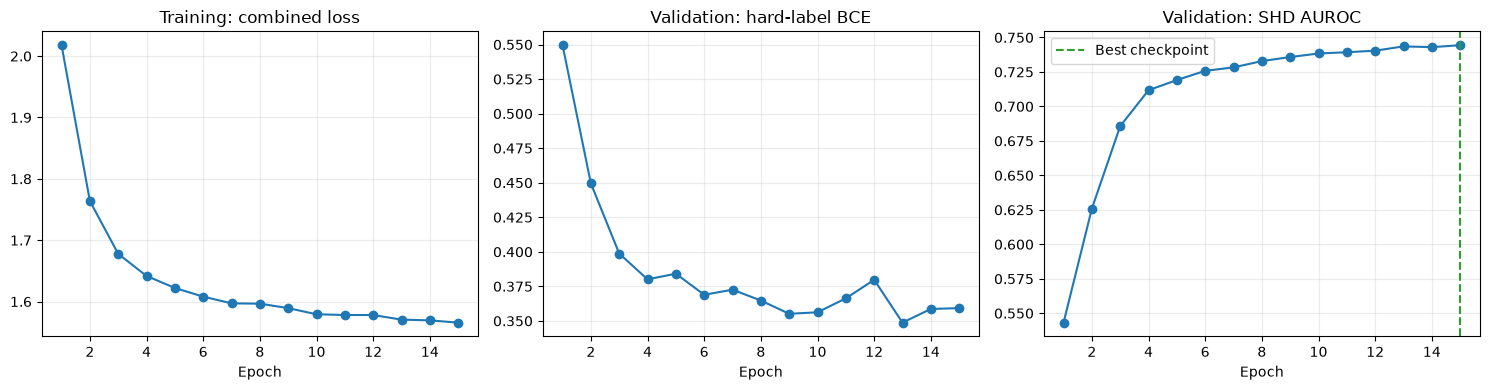

In [7]:
history = pd.DataFrame(json.loads((CHECKPOINT_DIR / "history.json").read_text()))
display(history)
best_row = history.loc[history["val_shd_auc"].idxmax()]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, column, title in zip(
    axes,
    ("train_loss", "val_loss", "val_shd_auc"),
    ("Training: combined loss", "Validation: hard-label BCE", "Validation: SHD AUROC"),
):
    axis.plot(history["epoch"], history[column], marker="o")
    axis.set(xlabel="Epoch", title=title)
    axis.grid(alpha=0.25)
axes[2].axvline(best_row["epoch"], color="tab:green", linestyle="--", label="Best checkpoint")
axes[2].legend()
fig.tight_layout()
plt.show()


## 7. Evaluate and compare the Student

**Run the cell below.** It reloads the best saved Student, evaluates it on the validation ECGs, and saves its predictions and an experiment summary.

- **If Teacher validation predictions are available:** the tables compare the Teacher and Student on the same ECGs. Mini mode prepares these predictions in Part 4.
- **If they are not available:** the tables show the Student's results alone.

The cell prints where the predictions and summary were saved. These are validation results; final Test evaluation comes after you choose the training settings.

<details>
<summary>Scores and saved results</summary>

The tables show overall SHD results and results for each of the 12 labels:

- **AUROC:** how well predictions rank positive examples above negative examples. Higher is better.
- **Brier score:** the average squared difference between predicted probabilities and true labels. Lower is better.

If the Teacher's validation run includes extra ECGs, only predictions for the selected Student validation ECGs are used in the comparison.

The Student prediction folder contains `predictions.npz`, `metadata.csv`, `manifest.json`, and `metrics.json`. `experiment_summary.json` is saved in `CHECKPOINT_DIR` alongside the training settings and history.

These results are not a full fairness or calibration audit. A score on a small validation subset is not directly comparable to Mini's published full-test AUROC of 0.820.

</details>


In [8]:
trained = load_student(checkpoint, mini_dir=MINI_DIR, device=DEVICE)
student_run_path = write_run(
    trained, "student", val, runs_root=RUNS_ROOT,
    batch_size=INFERENCE_BATCH_SIZE, device=DEVICE, seed=SEED,
    checkpoint_sha256=sha256_file(checkpoint), teacher_run=str(teacher_run_path),
    training_settings=TRAINING,
    purpose="dummy stand-in experiment" if TEACHER_SOURCE == "mini" else "teacher distillation",
)
student_run = load_run(student_run_path)
student_metrics = student_run.metrics
reference_metrics = None
if reference_run is not None:
    reference_logits = aligned_logits(reference_run, val.selected_metadata["row_id"].to_numpy())
    reference_metrics = basic_metrics({
        "probabilities": torch.sigmoid(reference_logits).numpy(),
        "labels": val.labels[val.indices],
        "label_mask": val.label_mask[val.indices],
    })

shd = LABEL_COLUMNS[SHD_INDEX]
rows = []
if reference_metrics is not None:
    rows.append({"model": "Mini (stand-in)" if TEACHER_SOURCE == "mini" else "Teacher",
                 "validation_ecgs": len(val), **reference_metrics[shd]})
rows.append({"model": "Student (best checkpoint)", "validation_ecgs": len(val), **student_metrics[shd]})
comparison = pd.DataFrame(rows)
display(comparison)

per_label = pd.DataFrame(student_metrics).T.rename(
    columns={"auroc": "student_auroc", "brier": "student_brier"},
)
if reference_metrics is not None:
    per_label["reference_auroc"] = pd.Series({name: values["auroc"] for name, values in reference_metrics.items()})
    per_label["reference_brier"] = pd.Series({name: values["brier"] for name, values in reference_metrics.items()})
display(per_label)

summary = {
    "experiment": EXPERIMENT_NAME, "teacher_source": TEACHER_SOURCE,
    "teacher_run": str(teacher_run_path), "code_commit": CODE_VERSION,
    "seed": SEED, "train_limit": TRAIN_LIMIT, "val_limit": VAL_LIMIT,
    "train_records": len(train), "val_records": len(val),
    "student_parameters": parameter_count, "training_settings": TRAINING,
    "epochs_completed": len(history), "best_epoch": int(best_row["epoch"]),
    "student_training_and_validation_seconds": training_seconds,
    "student_shd": student_metrics[shd],
    "reference_shd": None if reference_metrics is None else reference_metrics[shd],
    "checkpoint": str(checkpoint), "student_run": str(student_run_path),
}
(CHECKPOINT_DIR / "experiment_summary.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False) + "\n"
)
print("Saved Student validation run:", student_run_path)
print("History, settings, and summary:", CHECKPOINT_DIR)


,model,validation_ecgs,n_observed,n_positive,auroc,brier
0,Mini (stand-in),256,256,119,0.803472,0.179398
1,Student (best checkpoint),256,256,119,0.744403,0.223977


,n_observed,n_positive,student_auroc,student_brier,reference_auroc,reference_brier
lvef_lte_45_flag,256.0,51.0,0.767671,0.135808,0.860832,0.154101
lvwt_gte_13_flag,256.0,42.0,0.588563,0.153225,0.654206,0.216800
aortic_stenosis_moderate_or_greater_flag,256.0,19.0,0.822119,0.073275,0.868976,0.175684
aortic_regurgitation_moderate_or_greater_flag,256.0,6.0,0.874000,0.045618,0.814667,0.187468
mitral_regurgitation_moderate_or_greater_flag,256.0,20.0,0.810593,0.085854,0.800847,0.184589
tricuspid_regurgitation_moderate_or_greater_flag,256.0,23.0,0.809666,0.094487,0.873297,0.162386
pulmonary_regurgitation_moderate_or_greater_flag,256.0,2.0,0.787402,0.039197,0.671260,0.147389
rv_systolic_dysfunction_moderate_or_greater_flag,256.0,28.0,0.839599,0.093635,0.916980,0.142802
pericardial_effusion_moderate_large_flag,256.0,4.0,0.649802,0.079548,0.880952,0.188234
pasp_gte_45_flag,256.0,35.0,0.760181,0.121986,0.780608,0.185404


Saved Student validation run: /Users/sanjaykumar/repos/coms6998/compress_ECG/runs/dummy/mini_longer_v1/student/val
History, settings, and summary: /Users/sanjaykumar/repos/coms6998/compress_ECG/checkpoints/dummy/mini_longer_v1


## What to try next and what to share

**For another experiment, change the settings in Part 2, choose a new run name, and rerun from there.**

- **Use more data:** set `TRAIN_LIMIT` and `VAL_LIMIT` to `None`, and allow more training epochs.
- **Try other training settings:** compare learning rates, temperatures, and true-label weights using Validation.
- **Check whether distillation helps:** run once with `hard_label_weight = 1.0` so the Student learns from true labels alone. Keep the selected ECGs and initial seed the same for comparison.
- **Switch from Mini to the trained Teacher:** update `TEACHER_SOURCE` and the prediction folder paths in 2.2.

**For the next project steps:** share the best Student checkpoint for quantization and its validation prediction folder for the audit. Choose final settings before evaluating Test.

Keep Mini stand-in outputs under `runs/dummy/`. Keep patient-level predictions and checkpoints private, and clear notebook outputs before committing. Only reviewed aggregate results belong in the report.
